# [05.Explainability (Phase 5) -- SHAP on the @champion model]

MAE/residuals tell us *how* the model errs; SHAP tells us *why* it predicts what it does — which features drive a prediction, and in which direction. We answer three things:

1. **Global** — which features drive length-of-stay overall?
2. **Local** — why did *this* patient get their specific prediction?
3. **The ceiling** — for the long-stay patients the model under-predicts (see `04_posthoc_analysis`), do the features even push the prediction up, or does the model lack the signal to reach the tail?

> **Note: SHAP values are in log-space here.** The champion is the `log1p` variant: it trains on `log1p(LOS)`, so the model's raw output (what SHAP explains) is *log-days*, not days. **Direction and ranking of contributions are fully interpretable**; the magnitudes are in log-space, so don't read a SHAP value of `+0.3` as “+0.3 days”. We use `TreeExplainer` (exact and fast for tree models) on the **native** LightGBM model.


## 0. Setup — load the native model + test set

Load the LightGBM model via the **lightgbm flavor** (not pyfunc), so SHAP can read the tree structure directly. Rebuild the test set with the same transform used in training.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import mlflow
import mlflow.lightgbm

from los_pred.train import load_and_prepare, REGISTERED_MODEL, TRACKING_URI

mlflow.set_tracking_uri(TRACKING_URI)

# Native LightGBM model (an LGBMRegressor) — TreeExplainer needs the trees, not the
# flavor-agnostic pyfunc wrapper.
model = mlflow.lightgbm.load_model(f"models:/{REGISTERED_MODEL}@champion")

X_train, y_train, X_test, y_test, _ = load_and_prepare()
print("model loaded; X_test:", X_test.shape)

model loaded; X_test: (16953, 28)


## 1. Global feature importance

`TreeExplainer` computes exact SHAP values. The **beeswarm** shows, per feature, how each patient's value pushes the (log-space) prediction up (right) or down (left) — colour is the feature value. The **bar** ranks features by mean |SHAP| (average impact magnitude).

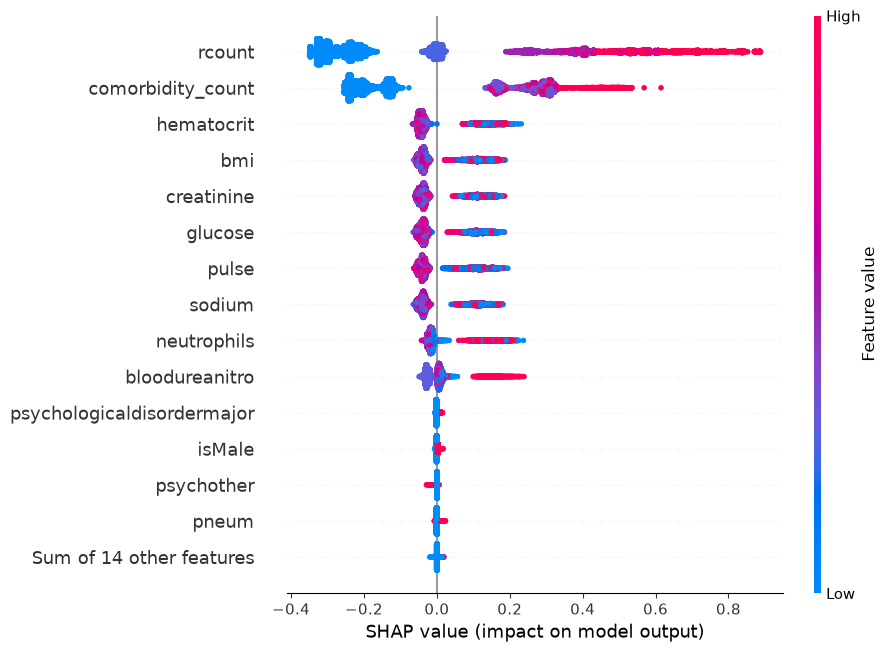

In [6]:
# SHAP values explain the RAW model output = log1p(LOS) — log-space (see header note).
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)          # Explanation: (n_samples, n_features)

shap.plots.beeswarm(shap_values, max_display=15)

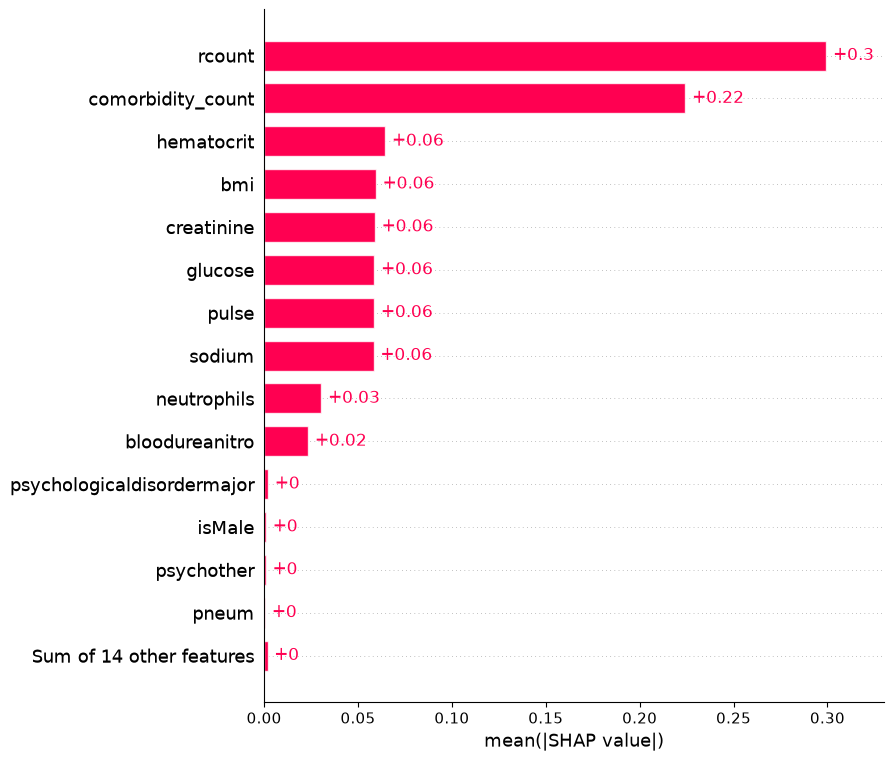

In [7]:
# Global importance = mean |SHAP| per feature.
shap.plots.bar(shap_values, max_display=15)

## 2. Local explanation — one prediction

A **waterfall** decomposes a single prediction: starting from the base value (average log-prediction), each feature nudges it up or down to the final log-prediction. Below we also convert that row's prediction back to days (`expm1` + floor-clip) so you can tie the explanation to the served number.

row 0: predicted 4.18 days  (actual 4 days)


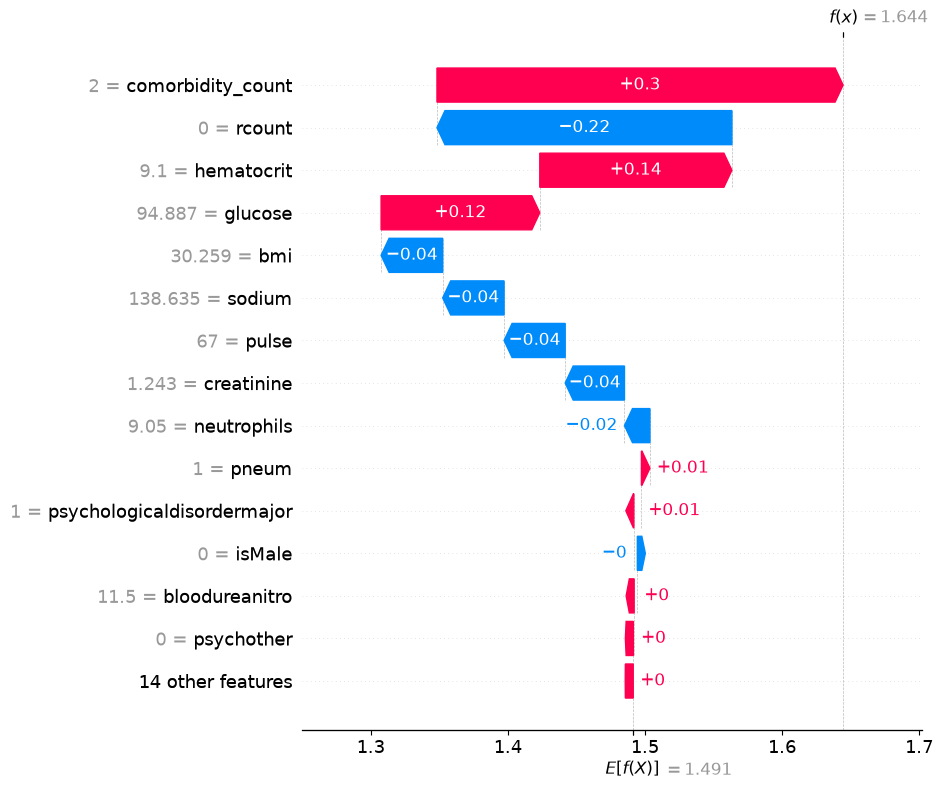

In [12]:
i = 0   # index of the test row to explain
raw_pred = model.predict(X_test.iloc[[i]])[0]              # log-space
pred_days = float(np.clip(np.expm1(raw_pred), 1, None))    # served value
print(f"row {i}: predicted {pred_days:.2f} days  (actual {int(y_test.iloc[i])} days)")

shap.plots.waterfall(shap_values[i], max_display=15)

## 3. The ceiling — why the model can't reach long stays


`04_posthoc_analysis` showed the model systematically under-predicts long stays. SHAP lets us ask *why*: for long-stay patients (LOS ≥ 10), which features carry the most weight, and are they pushing the prediction **up** enough? If even the top features contribute little for these rows, the model simply lacks the signal to reach the tail (consistent with the rare, capped long-stay data).

In [25]:
long_mask = y_test.to_numpy() >= 10
print(f"long-stay (LOS>=10) rows: {int(long_mask.sum())} of {len(y_test)}")

# Mean signed SHAP (log-space) per feature: overall vs the long-stay subset.
signed_all = shap_values.values.mean(0)
signed_long = shap_values.values[long_mask].mean(0)
cmp = (pd.DataFrame({
           "feature": X_test.columns,
           "mean_shap_all": signed_all,
           "mean_shap_long": signed_long,
       })
       .assign(shift=lambda d: d["mean_shap_long"] - d["mean_shap_all"])
       .sort_values("mean_shap_long", ascending=False))
cmp.head(15)

long-stay (LOS>=10) rows: 280 of 16953


,feature,mean_shap_all,mean_shap_long,shift
0,rcount,-0.000606,0.422216,0.422821
21,comorbidity_count,0.001646,0.165257,0.163611
12,hematocrit,0.000219,0.067632,0.067413
16,bloodureanitro,-0.000802,0.042383,0.043186
15,glucose,-0.000250,0.035162,0.035412
17,creatinine,-0.000133,0.033585,0.033718
18,bmi,0.000631,0.033345,0.032715
19,pulse,0.000276,0.032663,0.032387
14,sodium,-0.001210,0.029334,0.030544
13,neutrophils,-0.000466,0.022168,0.022633


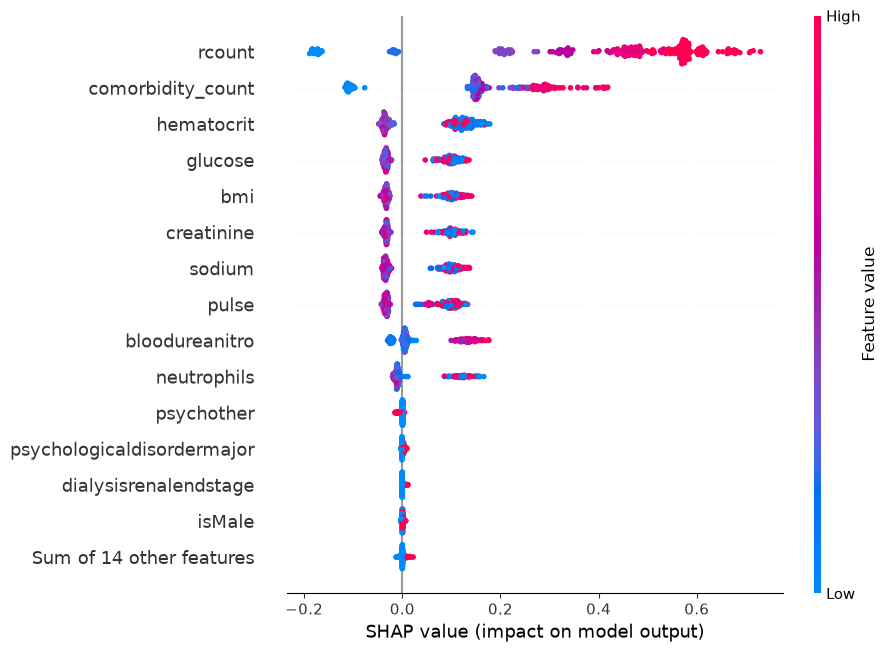

In [24]:
# Beeswarm restricted to the long-stay patients — do features push up (right)?
shap.plots.beeswarm(shap_values[long_mask], max_display=15)

## 4 · Findings

- **Top global drivers of LOS:** `rcount` (readmission count) and `comorbidity_count` dominate. Lab values (hematocrit, glucose, blood urea nitrogen, creatinine) show smaller but consistent contributions.

- **Direction that matches clinical intuition?** Yes. More readmissions and higher comorbidity burden both push predictions up — aligned with clinical expectation that sicker patients (more prior admissions, more comorbidities) have longer stays.

- **Local example (§2):** Row 0 predicted 4.18 days vs. actual 4 days — accurate. The waterfall shows how individual feature values (patient's rcount, lab values, etc.) combined to reach that prediction.

- **Ceiling (§3):** Yes, top features push the prediction UP meaningfully for long-stay patients (rcount SHAP = +0.42, comorbidity_count = +0.17 in log-space), but the model still under-predicts. Root cause: **data scarcity**. Only 280/16,953 test rows (1.6%) are LOS ≥ 10; the training data is capped at LOS=17 with few examples in the tail. The model learned what features matter but lacks sufficient long-stay examples to calibrate their magnitude.

- **Key evidence — the model *does* behave differently (correctly) for long-stayers:** `rcount`'s mean SHAP is **~0 across all patients** (+0.0006) but **+0.42 for the long-stay subset**; `comorbidity_count` similarly jumps from ~0 to +0.17. The near-zero overall value is just +/− contributions cancelling across typical patients — it is *not* that the feature is unused. This all-vs-long contrast is the strongest single piece of evidence that the model correctly *recognises* long-stayers and pushes their predictions up; the shortfall is one of **magnitude/calibration** (the scarce, capped tail), not of the model ignoring the signal.

- **Clinical write-up (plan deliverable):** The model predicts length of stay primarily from readmission history and comorbidity burden—both strong, clinically intuitive drivers. For typical admissions (LOS 1–9 days), predictions are accurate. However, the model systematically under-predicts long stays (LOS ≥ 10 days) because the training data contains few long-stay examples (capped at 17 days, only 1.6% of data). This is a data limitation, not a model flaw; clinicians should trust predictions for routine cases but apply clinical judgment to high-risk patients (many readmissions, multiple comorbidities) where the model may underestimate stay duration.